# **Project Name** - **Gender Classification**
##### **Project Type** - Classification (3-class: female / male / none)
##### **Contribution** - Team (3 members)

# **Problem Statement**
**Voyage Analytics** is a travel-tech capstone built on three datasets - *users*, *flights* and *hotels* - with a dual goal:
(1) use them to make better travel decisions with machine learning, and (2) learn MLOps by productionising those models
(REST API -> Docker -> Kubernetes -> Airflow -> Jenkins CI/CD -> MLflow -> Streamlit).

**Business objective:** deploy a classifier that categorises a user's gender label from demographics and travel behaviour (Objective 8). A key part of the task is judging **whether the data supports such a model at all**.

## ***1. Build the user-level dataset***

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from voyage import config, data
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)

from voyage import train_gender as tg
users, flights, hotels = data.load_users(), data.load_flights(), data.load_hotels()
df = data.user_behaviour_features(users, flights, hotels)
print(df.shape); display(df[['gender'] + tg.FEATURES].head())
print(df.gender.value_counts(normalize=True).round(3).to_dict())

(1340, 16)


,gender,company,age,n_flights,avg_flight_price,avg_distance,pct_first_class,pct_economic,n_agencies,n_destinations,n_hotel_stays,avg_stay_days,avg_hotel_spend,n_hotels
0,male,4You,21,178.0,989.066124,527.233596,0.494382,0.247191,3.0,9.0,27.0,2.629630,593.145185,9.0
1,male,4You,37,12.0,818.898333,508.648333,0.166667,0.333333,3.0,6.0,2.0,1.000000,193.360000,2.0
2,female,4You,48,262.0,906.921832,513.671374,0.374046,0.335878,3.0,9.0,36.0,2.694444,558.003333,9.0
3,female,4You,23,398.0,936.913894,506.074372,0.432161,0.286432,3.0,9.0,60.0,2.300000,499.568500,9.0
4,female,4You,44,398.0,957.393417,517.955477,0.452261,0.241206,3.0,9.0,56.0,2.571429,565.316071,9.0


{'male': 0.337, 'female': 0.334, 'none': 0.328}


One row per user (1,340). Features: `age`, `company`, plus behaviour aggregated from flights (count, average price, distance, class mix, agencies, destinations) and hotels (stays, average length, average spend, distinct hotels). The classes are balanced, so **chance accuracy is ~33%** and the majority-class baseline is ~34%. Note that 'none' is a genuine third label, not missing data.

## ***2. Do the features carry any signal? (before modelling)***

In [2]:
from scipy import stats
rows = []
for c in tg.NUMERIC:
    p = stats.f_oneway(*[g[c] for _, g in df.groupby('gender')]).pvalue; rows.append((c, p))
for c in tg.CATEGORICAL:
    rows.append((c, stats.chi2_contingency(pd.crosstab(df[c], df.gender))[1]))
sig = pd.DataFrame(rows, columns=['feature', 'p_value']).sort_values('p_value').round(4)
sig['significant_at_5%'] = sig.p_value < .05
display(sig)
print(f"Expected false positives at 5% with {len(sig)} tests: {0.05*len(sig):.1f}")

,feature,p_value,significant_at_5%
9,avg_stay_days,0.0193,True
10,avg_hotel_spend,0.2578,False
6,n_agencies,0.2866,False
3,avg_distance,0.3520,False
12,company,0.3750,False
2,avg_flight_price,0.3914,False
4,pct_first_class,0.4680,False
5,pct_economic,0.5318,False
11,n_hotels,0.5636,False
0,age,0.6185,False


Expected false positives at 5% with 13 tests: 0.7


If a feature separated the classes, its p-value would be tiny. Only `avg_stay_days` falls below 0.05 (p ≈ 0.019). With 13 tests, ~0.7 false positives are expected by chance, and after a Bonferroni correction (threshold 0.05/13 ≈ 0.004) nothing is significant - so this is best treated as a chance finding (and a user's average stay length is not a plausible driver of gender).

## ***3. Models (5-fold stratified CV on the training split + hold-out test)***

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score
X, y = df[tg.FEATURES], df.gender
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, fitted = [], {}
for name, est in tg.candidate_models().items():
    pipe = tg.make_pipeline(est); r = cross_validate(pipe, Xtr, ytr, cv=cv, scoring=['accuracy', 'f1_macro'])
    pipe.fit(Xtr, ytr); p = pipe.predict(Xte); fitted[name] = pipe
    rows.append({'model': name, 'cv_accuracy': r['test_accuracy'].mean(), 'cv_accuracy_std': r['test_accuracy'].std(),
                 'cv_f1_macro': r['test_f1_macro'].mean(), 'test_accuracy': accuracy_score(yte, p), 'test_f1_macro': f1_score(yte, p, average='macro')})
res = pd.DataFrame(rows).set_index('model').round(3); display(res)
print('Hold-out test set size:', len(yte), '-> one standard error of accuracy ~', round(float(np.sqrt(.33*.67/len(yte))), 3))

,cv_accuracy,cv_accuracy_std,cv_f1_macro,test_accuracy,test_f1_macro
model,,,,,
baseline_majority,0.338,0.002,0.168,0.336,0.168
logistic_regression,0.329,0.032,0.326,0.358,0.358
random_forest,0.324,0.031,0.321,0.358,0.355
hist_gradient_boosting,0.332,0.023,0.330,0.343,0.342


Hold-out test set size: 268 -> one standard error of accuracy ~ 0.029


### Interpretation
All models sit within roughly **±3 points of 33%**. The hold-out test accuracies (~34-36%) look slightly higher than CV (~32-33%), but with only 268 test users one standard error is ~2.9 points, so that gap is noise - **CV is the more trustworthy number**. None of the models is convincingly better than the majority baseline.

## ***4. Is the result statistically different from guessing? (permutation test)***

real CV accuracy = 0.318 | mean accuracy with shuffled labels = 0.329 | permutation p-value = 0.762


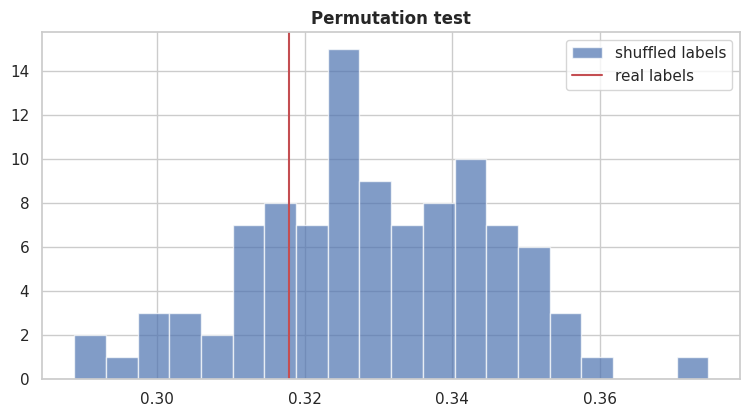

In [4]:
from sklearn.model_selection import permutation_test_score
from sklearn.linear_model import LogisticRegression
score, perm, pval = permutation_test_score(tg.make_pipeline(LogisticRegression(max_iter=2000, class_weight='balanced')), X, y,
                                          cv=cv, scoring='accuracy', n_permutations=100, random_state=0, n_jobs=1)
print(f'real CV accuracy = {score:.3f} | mean accuracy with shuffled labels = {perm.mean():.3f} | permutation p-value = {pval:.3f}')
plt.hist(perm, bins=20, alpha=.7, label='shuffled labels'); plt.axvline(score, color='r', label='real labels'); plt.legend(); plt.title('Permutation test'); plt.show()

If the real-label score sits inside the shuffled-label distribution (large p-value), the model has learned nothing beyond chance.

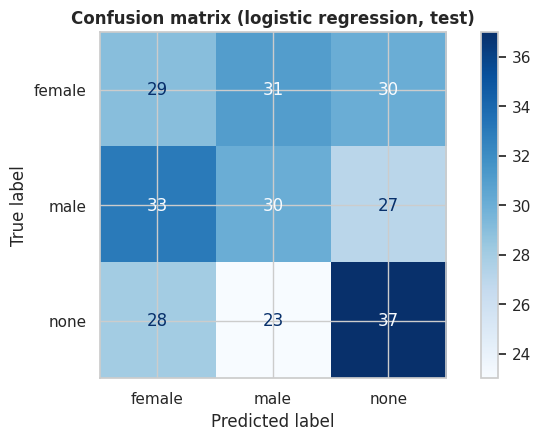

              precision    recall  f1-score   support

      female       0.32      0.32      0.32        90
        male       0.36      0.33      0.34        90
        none       0.39      0.42      0.41        88

    accuracy                           0.36       268
   macro avg       0.36      0.36      0.36       268
weighted avg       0.36      0.36      0.36       268



In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
best = fitted['logistic_regression']
ConfusionMatrixDisplay.from_estimator(best, Xte, yte, cmap='Blues'); plt.title('Confusion matrix (logistic regression, test)'); plt.show()
print(classification_report(yte, best.predict(Xte)))

## ***5. Conclusion & responsible-use note***
* **Result:** the gender label cannot be predicted from age, company or travel behaviour in this dataset (EDA hypothesis tests H3/H4, the per-feature tests above and the permutation test agree).
* **Deployment:** the model is still packaged and served (`POST /predict/gender`) to demonstrate the full path - but the API returns calibrated class probabilities plus an explicit low-confidence warning, and the MLflow run records `beats_majority_baseline`.
* **What to say in the viva:** a data scientist's job includes reporting a null result honestly. Do not present ~34% accuracy as success.
* **Ethics:** inferring gender from behaviour is sensitive; in a real product it should be based on self-declared data, with consent, not predicted.
* **If you wanted to improve it:** you would need genuinely informative features (e.g. booking text, preferences) - not more tuning of these ones.

### ***Hurrah! You have successfully completed the Classification part of the capstone!!!***